In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy

In [2]:
custdf = pd.read_csv("custdata.tsv", sep="\t")

In [3]:
custdf.shape

(1000, 11)

In [4]:
custdf.head()

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
0,2068,F,NaN,11300,Married,True,Homeowner free and clear,False,2.0,49.0,Michigan
1,2073,F,NaN,0,Married,True,Rented,True,3.0,40.0,Florida
2,2848,M,True,4500,Never Married,False,Rented,True,3.0,22.0,Georgia
3,5641,M,True,20000,Never Married,False,Occupied with no rent,False,0.0,22.0,New Mexico
4,6369,F,True,12000,Never Married,True,Rented,True,1.0,31.0,Florida


In [5]:
custdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   custid        1000 non-null   int64  
 1   sex           1000 non-null   str    
 2   is.employed   672 non-null    object 
 3   income        1000 non-null   int64  
 4   marital.stat  1000 non-null   str    
 5   health.ins    1000 non-null   bool   
 6   housing.type  944 non-null    str    
 7   recent.move   944 non-null    object 
 8   num.vehicles  944 non-null    float64
 9   age           1000 non-null   float64
 10  state.of.res  1000 non-null   str    
dtypes: bool(1), float64(2), int64(2), object(2), str(4)
memory usage: 115.8+ KB


In [6]:
custdf.describe()

,custid,income,num.vehicles,age
count,1.000000e+03,1000.000000,944.000000,1000.000000
mean,6.984997e+05,53504.771000,1.916314,51.699815
std,4.135083e+05,65478.065729,1.101618,18.863433
min,2.068000e+03,-8700.000000,0.000000,0.000000
25%,3.456668e+05,14600.000000,1.000000,38.000000
50%,6.934030e+05,35000.000000,2.000000,50.000000
75%,1.044606e+06,67000.000000,2.000000,64.000000
max,1.414286e+06,615000.000000,6.000000,146.680197


<Axes: >

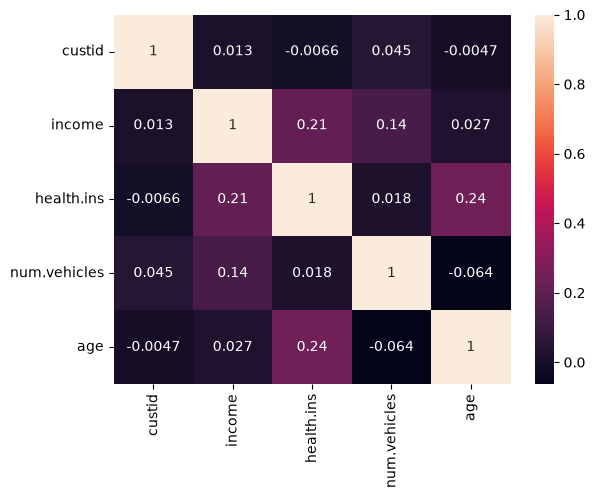

In [7]:
sns.heatmap(custdf.corr(numeric_only=True), annot=True)

Without any cleaning of the dataset, the correlation values for all combinations of columns yields extremely minimal r values. Let us see how this contrasts with cleaned data.

In [8]:
custdf.duplicated().sum()

np.int64(0)

In [9]:
custdf.isna().sum()

custid            0
sex               0
is.employed     328
income            0
marital.stat      0
health.ins        0
housing.type     56
recent.move      56
num.vehicles     56
age               0
state.of.res      0
dtype: int64

<Axes: >

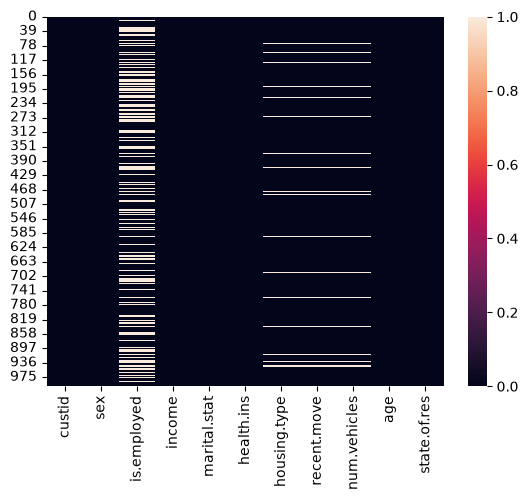

In [10]:
sns.heatmap(custdf.isna())

To begin with, many rows are missing values for one or more columns. It appears that missing values for "housing.type", "recent.move", and "num.vehicles" are all linked; a missing value for one is a missing value for the other two. A likely explanation is that those 56 rows represent individuals who filled out the form before those three fields were added to the survey.

Additionally, the "is.employed" column by far has the most missing values. We will view some of these missing-value rows then determine next steps.

In [11]:
custdf[custdf["housing.type"].isna()].head(15)

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
17,26057,M,True,30000,Married,True,NaN,NaN,NaN,28.0,Florida
55,68013,M,NaN,100,Divorced/Separated,False,NaN,NaN,NaN,28.0,California
72,90303,M,NaN,0,Never Married,False,NaN,NaN,NaN,45.0,Kentucky
96,115100,M,NaN,0,Never Married,False,NaN,NaN,NaN,29.0,California
123,151678,M,NaN,0,Never Married,False,NaN,NaN,NaN,34.0,Georgia
133,167154,M,NaN,0,Never Married,False,NaN,NaN,NaN,31.0,New Jersey
177,220142,F,NaN,0,Never Married,True,NaN,NaN,NaN,18.0,Arkansas
188,249492,F,NaN,10100,Widowed,True,NaN,NaN,NaN,93.0,Georgia
196,259807,M,NaN,440,Married,True,NaN,NaN,NaN,49.0,West Virginia
200,268667,M,NaN,200,Never Married,True,NaN,NaN,NaN,31.0,Pennsylvania


Because "housing.type", "recent.move", and "num.vehicles" are all closely linked, viewing rows that are missing "housing.type" also displays the rows that are missing the other two columns.

This set of rows with missing data is comprised of 56 rows. In the scope of the larger dataset, which has 1000 rows total, dropping these 56 rows will not decrease our sample size to the point of compromising on the quality of the analysis. So let us begin by dropping these rows.

In [12]:
custdf = custdf.dropna(subset=["housing.type"])

In [13]:
custdf.shape

(944, 11)

In [14]:
custdf.isna().sum()

custid            0
sex               0
is.employed     280
income            0
marital.stat      0
health.ins        0
housing.type      0
recent.move       0
num.vehicles      0
age               0
state.of.res      0
dtype: int64

In [15]:
custdf[custdf["housing.type"].isna()].head(15)

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res


As we can see above, the rows that were missing "housing.type", "recent.move", and "num.vehicles" have been dropped from our dataframe.

Next, let us look at the column with a much longer list of null rows: the "is.employed" column.

In [16]:
custdf[custdf["is.employed"].isna()].head(15)

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
0,2068,F,NaN,11300,Married,True,Homeowner free and clear,False,2.0,49.0,Michigan
1,2073,F,NaN,0,Married,True,Rented,True,3.0,40.0,Florida
8,14989,M,NaN,9400,Married,True,Rented,False,2.0,44.0,Illinois
10,16551,F,NaN,7000,Married,True,Homeowner with mortgage/loan,False,2.0,46.0,Georgia
16,25863,M,NaN,41000,Divorced/Separated,True,Homeowner with mortgage/loan,False,1.0,70.0,Virginia
19,27214,M,NaN,18800,Married,True,Homeowner free and clear,False,2.0,68.0,Ohio
29,38827,F,NaN,9700,Married,True,Homeowner with mortgage/loan,False,2.0,72.0,Oklahoma
31,40449,M,NaN,13000,Married,True,Homeowner free and clear,False,3.0,84.0,Kentucky
32,42374,M,NaN,7800,Never Married,True,Homeowner free and clear,False,1.0,65.0,Kentucky
34,46791,M,NaN,22700,Married,True,Homeowner free and clear,False,2.0,67.0,Oklahoma


There seems to be no clear pattern or reason behind these missing rows, so it is hard to say whether to keep them or not. For the sake of having a tighter dataset with less superfluous information, we will make a note of it and then drop these rows.

In [17]:
custdf = custdf.dropna(subset=["is.employed"])

In [18]:
custdf.shape

(664, 11)

In [19]:
custdf.isna().sum()

custid          0
sex             0
is.employed     0
income          0
marital.stat    0
health.ins      0
housing.type    0
recent.move     0
num.vehicles    0
age             0
state.of.res    0
dtype: int64

In [20]:
custdf.describe()

,custid,income,num.vehicles,age
count,6.640000e+02,664.000000,664.000000,664.000000
mean,7.050258e+05,66816.153614,2.031627,46.333458
std,4.064712e+05,70617.149428,1.089049,15.403896
min,2.848000e+03,-8700.000000,0.000000,0.000000
25%,3.567442e+05,25375.000000,1.000000,36.000000
50%,7.165195e+05,45000.000000,2.000000,46.000000
75%,1.042425e+06,82250.000000,3.000000,55.000000
max,1.414286e+06,615000.000000,6.000000,146.680197


In [21]:
custdf.head(10)

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
2,2848,M,True,4500,Never Married,False,Rented,True,3.0,22.0,Georgia
3,5641,M,True,20000,Never Married,False,Occupied with no rent,False,0.0,22.0,New Mexico
4,6369,F,True,12000,Never Married,True,Rented,True,1.0,31.0,Florida
5,8322,F,True,180000,Never Married,True,Homeowner with mortgage/loan,False,1.0,40.0,New York
6,8521,M,True,120000,Never Married,True,Homeowner free and clear,True,1.0,39.0,Idaho
7,12195,M,True,40000,Married,True,Rented,False,3.0,48.0,Michigan
9,15917,F,True,24000,Divorced/Separated,True,Homeowner free and clear,False,1.0,70.0,North Carolina
11,17134,M,True,220000,Married,True,Homeowner free and clear,True,2.0,33.0,Indiana
12,17946,F,True,85000,Divorced/Separated,True,Rented,False,1.0,51.0,New Hampshire
13,18487,F,True,89200,Divorced/Separated,True,Homeowner with mortgage/loan,False,1.0,63.0,Georgia


In [22]:
custdf.duplicated().sum()

np.int64(0)

One last cleaning check is whether there are rows with impossible values using .describe() above. The one very obvious issue is in the "age" column: the maximum value is 146 years, which is totally unrealistic. Time to pursue that lead and explore any other impossible age values:

In [23]:
custdf[(custdf["age"] >= 90)]

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
212,287882,M,True,60000,Married,True,Rented,True,2.0,137.700030,Florida
286,397230,F,True,31200,Married,True,Rented,False,2.0,136.052160,Texas
593,843811,F,True,40000,Never Married,True,Homeowner with mortgage/loan,False,1.0,146.680197,Indiana
625,875771,M,False,175200,Married,True,Homeowner with mortgage/loan,False,3.0,124.845087,Arkansas
752,1047534,M,True,200000,Married,True,Homeowner with mortgage/loan,False,4.0,130.401605,Washington
926,1303929,F,False,43400,Never Married,True,Rented,False,1.0,126.737284,West Virginia


It looks like there are 6 rows that have implausibly high values for the "age" column. Now is the time to drop these rows from the dataset, too.

In [24]:
custdf = custdf[(custdf["age"] <= 90)]

In [25]:
custdf[(custdf["age"] >= 90)]

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res


In [26]:
custdf.shape

(658, 11)

In [27]:
custdf.describe()

,custid,income,num.vehicles,age
count,6.580000e+02,658.000000,658.000000,658.000000
mean,7.042264e+05,66589.857143,2.030395,45.536474
std,4.068413e+05,70593.647604,1.089169,12.982580
min,2.848000e+03,-8700.000000,0.000000,0.000000
25%,3.567068e+05,25000.000000,1.000000,36.000000
50%,7.162100e+05,45000.000000,2.000000,46.000000
75%,1.041932e+06,82000.000000,3.000000,55.000000
max,1.414286e+06,615000.000000,6.000000,88.000000


In [28]:
custdf.info()

<class 'pandas.DataFrame'>
Index: 658 entries, 2 to 999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   custid        658 non-null    int64  
 1   sex           658 non-null    str    
 2   is.employed   658 non-null    object 
 3   income        658 non-null    int64  
 4   marital.stat  658 non-null    str    
 5   health.ins    658 non-null    bool   
 6   housing.type  658 non-null    str    
 7   recent.move   658 non-null    object 
 8   num.vehicles  658 non-null    float64
 9   age           658 non-null    float64
 10  state.of.res  658 non-null    str    
dtypes: bool(1), float64(2), int64(2), object(2), str(4)
memory usage: 82.2+ KB


In [29]:
custdf.head(15)

,custid,sex,is.employed,income,marital.stat,health.ins,housing.type,recent.move,num.vehicles,age,state.of.res
2,2848,M,True,4500,Never Married,False,Rented,True,3.0,22.0,Georgia
3,5641,M,True,20000,Never Married,False,Occupied with no rent,False,0.0,22.0,New Mexico
4,6369,F,True,12000,Never Married,True,Rented,True,1.0,31.0,Florida
5,8322,F,True,180000,Never Married,True,Homeowner with mortgage/loan,False,1.0,40.0,New York
6,8521,M,True,120000,Never Married,True,Homeowner free and clear,True,1.0,39.0,Idaho
7,12195,M,True,40000,Married,True,Rented,False,3.0,48.0,Michigan
9,15917,F,True,24000,Divorced/Separated,True,Homeowner free and clear,False,1.0,70.0,North Carolina
11,17134,M,True,220000,Married,True,Homeowner free and clear,True,2.0,33.0,Indiana
12,17946,F,True,85000,Divorced/Separated,True,Rented,False,1.0,51.0,New Hampshire
13,18487,F,True,89200,Divorced/Separated,True,Homeowner with mortgage/loan,False,1.0,63.0,Georgia


We now have a clean dataset to work with. It is time to return to the correlation between columns and proceed with the rest of our analysis.

<Axes: >

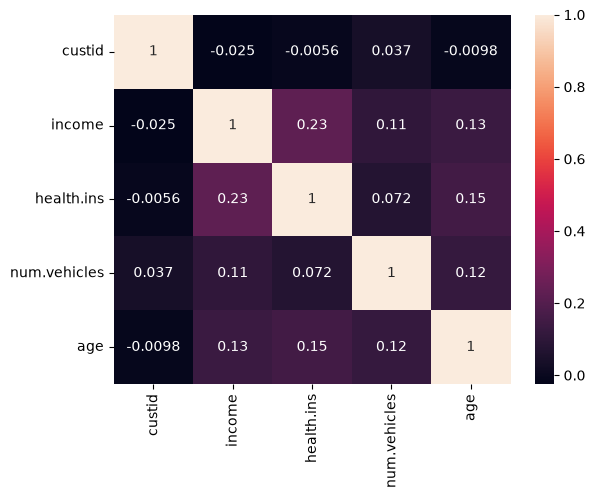

In [30]:
sns.heatmap(custdf.corr(numeric_only=True), annot=True)

The r values have shifted slightly now that the data has been cleaned. While the difference may not be huge, faulty or incomplete rows can nonetheless distort a dataset and its analysis if erroneous values are not found in time.

It appears that the strongest correlation is between the "income" and "health.ins" columns, which sounds like it reflects reality. This relationship would not have been clearly the strongest one if analysis had come before cleaning.

I consulted the pandas User Guide:
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.dropna.html